# Assignment 9: Image Processing – LBP and Image Denoising

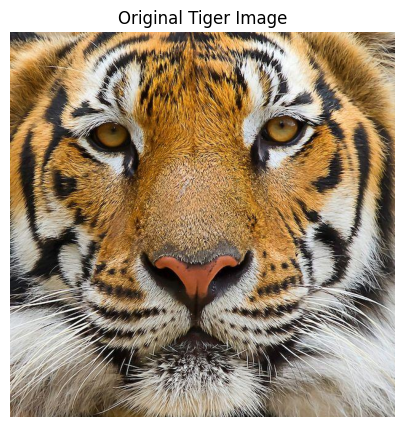

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener

img = cv2.imread('/content/new_image2.jpeg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 5))
plt.imshow(img)
plt.title("Original Tiger Image")
plt.axis("off")
plt.show()

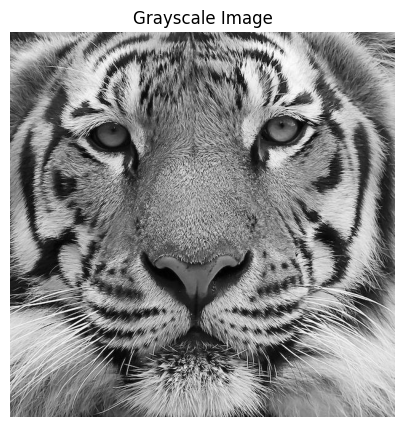

In [2]:
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(6, 5))
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

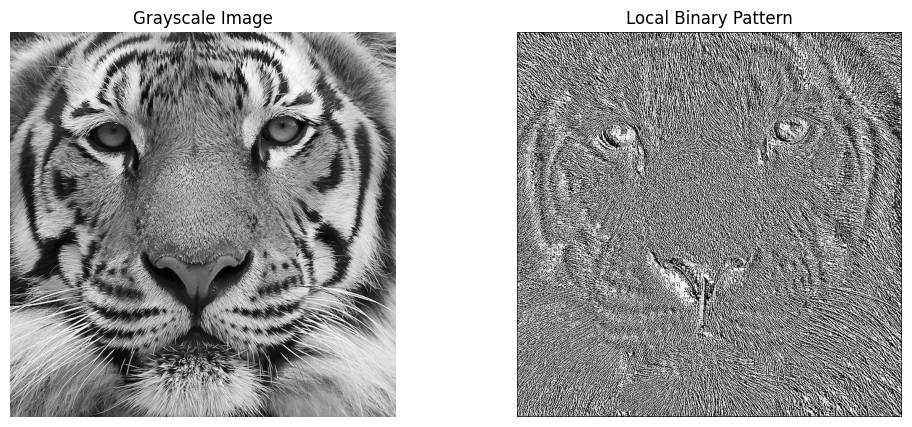

In [3]:
lbp = np.zeros_like(gray)

for i in range(1, gray.shape[0] - 1):
    for j in range(1, gray.shape[1] - 1):
        center = gray[i, j]
        binary = 0

        neighbors = [
            gray[i-1, j-1], gray[i-1, j],
            gray[i-1, j+1], gray[i, j+1],
            gray[i+1, j+1], gray[i+1, j],
            gray[i+1, j-1], gray[i, j-1]
        ]

        for k in range(8):
            if neighbors[k] >= center:
                binary += 1 << k

        lbp[i, j] = binary

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title("Local Binary Pattern")
plt.axis("off")

plt.show()

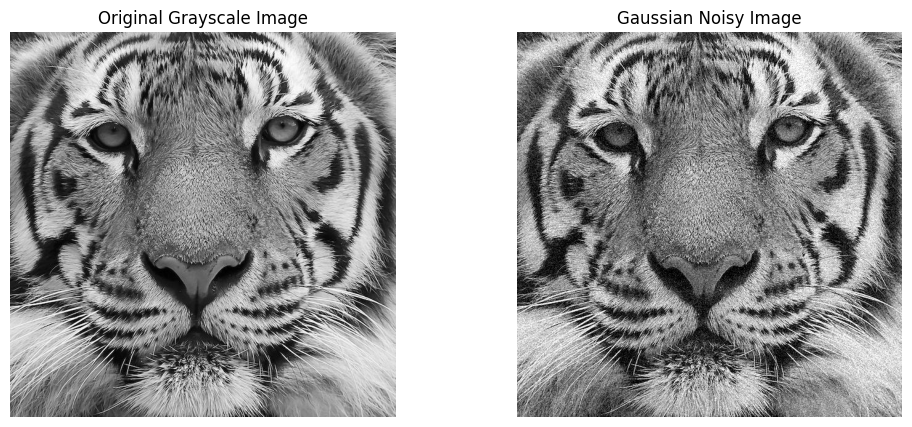

In [4]:
gaussian_noise = np.random.normal(0, 25, gray.shape)
gaussian_noisy = gray.astype(np.float32) + gaussian_noise
gaussian_noisy = np.clip(gaussian_noisy, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.show()

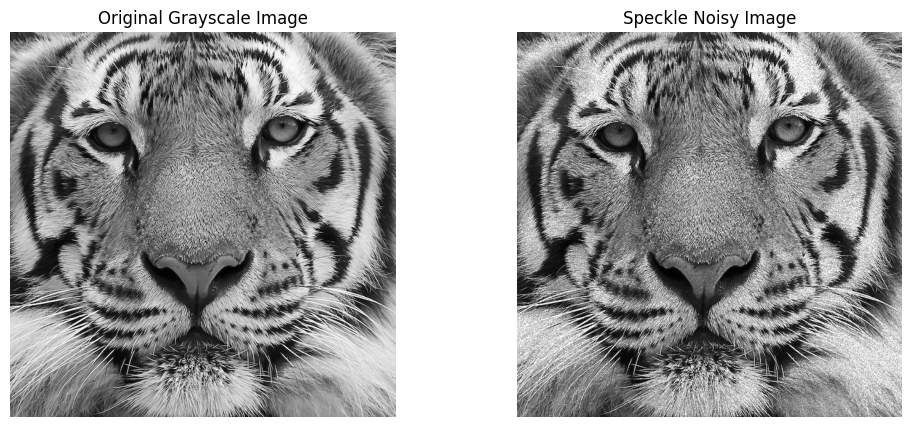

In [5]:
speckle_noise = np.random.normal(0, 0.15, gray.shape)
speckle_noisy = gray.astype(np.float32) / 255
speckle_noisy = speckle_noisy + speckle_noisy * speckle_noise
speckle_noisy = np.clip(speckle_noisy * 255, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(speckle_noisy, cmap='gray')
plt.title("Speckle Noisy Image")
plt.axis("off")

plt.show()

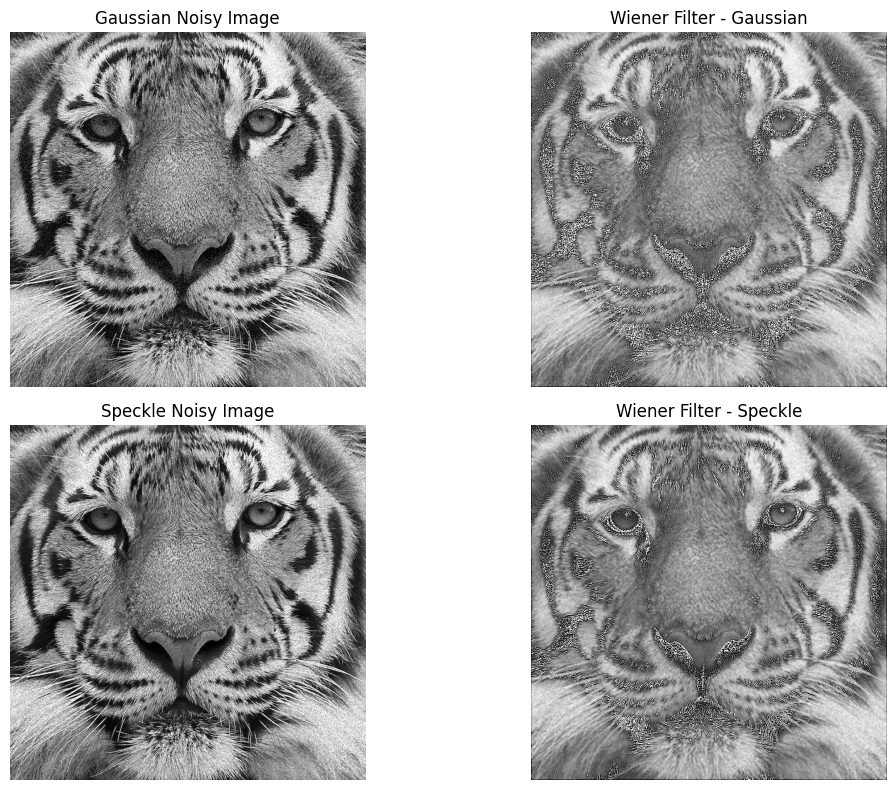

In [6]:
wiener_gaussian = wiener(gaussian_noisy, (3, 3))
wiener_gaussian = np.clip(wiener_gaussian, 0, 255).astype(np.uint8)

wiener_speckle = wiener(speckle_noisy, (3, 3))
wiener_speckle = np.clip(wiener_speckle, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(wiener_gaussian, cmap='gray')
plt.title("Wiener Filter - Gaussian")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(speckle_noisy, cmap='gray')
plt.title("Speckle Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(wiener_speckle, cmap='gray')
plt.title("Wiener Filter - Speckle")
plt.axis("off")

plt.tight_layout()
plt.show()

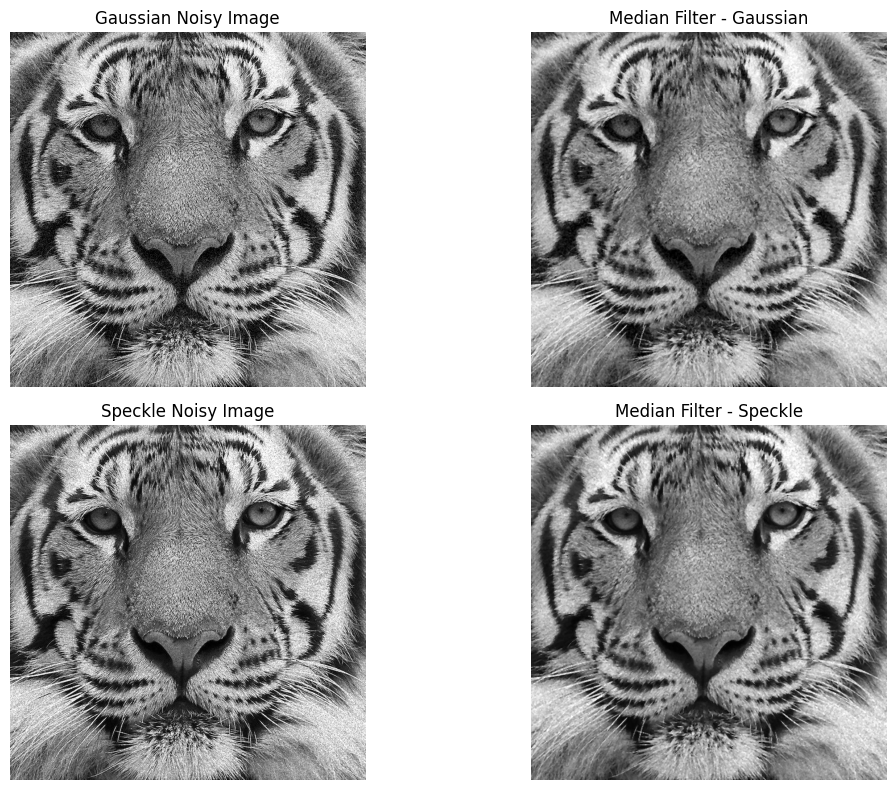

In [7]:
median_gaussian = cv2.medianBlur(gaussian_noisy, 3)
median_speckle = cv2.medianBlur(speckle_noisy, 3)

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(median_gaussian, cmap='gray')
plt.title("Median Filter - Gaussian")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(speckle_noisy, cmap='gray')
plt.title("Speckle Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(median_speckle, cmap='gray')
plt.title("Median Filter - Speckle")
plt.axis("off")

plt.tight_layout()
plt.show()

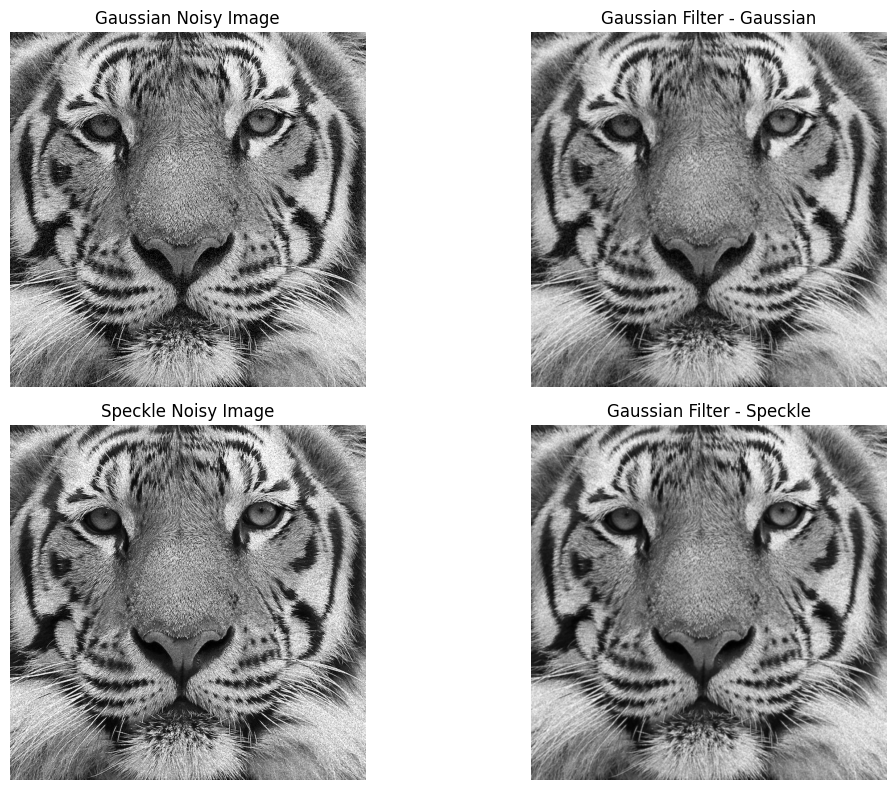

In [8]:
gaussian_gaussian = cv2.GaussianBlur(gaussian_noisy, (3, 3), 0)
gaussian_speckle = cv2.GaussianBlur(speckle_noisy, (3, 3), 0)

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(gaussian_gaussian, cmap='gray')
plt.title("Gaussian Filter - Gaussian")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(speckle_noisy, cmap='gray')
plt.title("Speckle Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(gaussian_speckle, cmap='gray')
plt.title("Gaussian Filter - Speckle")
plt.axis("off")

plt.tight_layout()
plt.show()

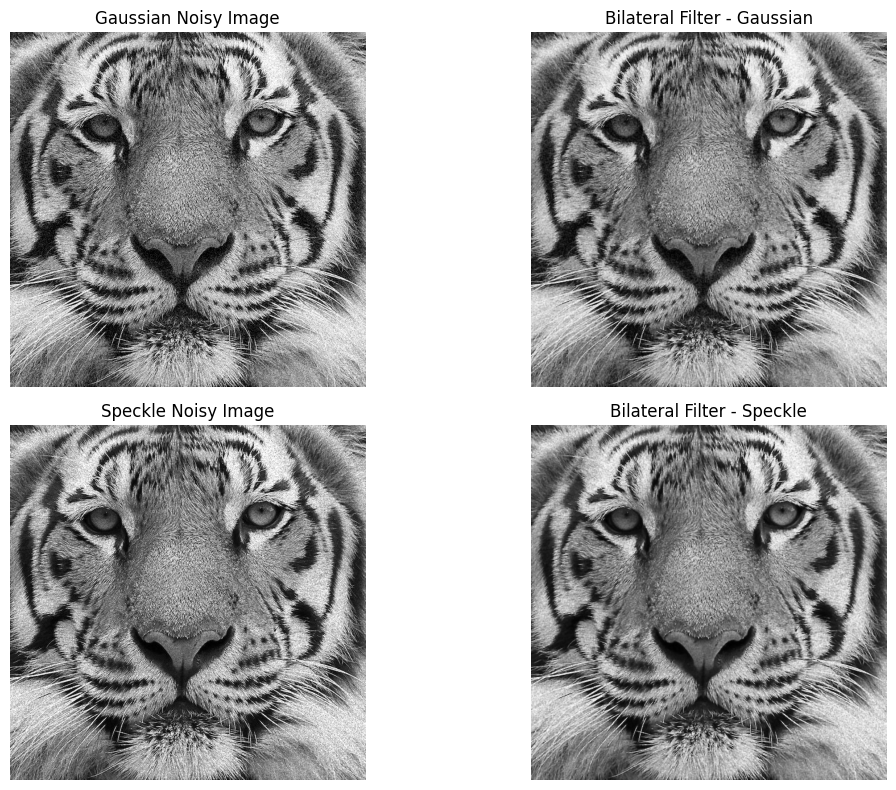

In [10]:
bilateral_gaussian = cv2.bilateralFilter(gaussian_noisy, 3, 75, 75)
bilateral_speckle = cv2.bilateralFilter(speckle_noisy, 3, 75, 75)

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(bilateral_gaussian, cmap='gray')
plt.title("Bilateral Filter - Gaussian")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(speckle_noisy, cmap='gray')
plt.title("Speckle Noisy Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(bilateral_speckle, cmap='gray')
plt.title("Bilateral Filter - Speckle")
plt.axis("off")

plt.tight_layout()
plt.show()

## Conclusion

In this assignment, Local Binary Pattern (LBP) was implemented on a grayscale image. Gaussian and Speckle noise were added to the image. Four denoising filters, namely Wiener, Median, Gaussian, and Bilateral filters, were applied to remove noise.

The results show that each filter reduces noise differently. These techniques help improve image quality while preserving important details and edges.